# APIs: el tiempo con Open-Meteo

## 0. Comprobación

In [2]:
import pandas as pd 
import numpy as np
import matplotlib

## 1. Qué es una API

Enlaces de la clase:

- https://robohash.org/TuNombre
- https://robohash.org/TuNombre?set=set4
- https://api.qrserver.com/v1/create-qr-code/?data=Hola&size=300x300
- https://quickchart.io/chart?c={type:'bar',data:{labels:['Lunes','Martes','Miércoles'],datasets:[{label:'Cafés',data:[30,45,28]}]}}
- https://api.frankfurter.dev/v1/latest?amount=50&base=EUR&symbols=USD,GBP
- https://api.wheretheiss.at/v1/satellites/25544
- https://pokeapi.co/api/v2/pokemon/pikachu
- https://open-meteo.com/en/pricing

## 2. De la API a pandas

Documentación: https://open-meteo.com/en/docs

In [3]:
latitud = "40.42"     # Madrid. Entre comillas: son trozos del texto de la URL
longitud = "-3.70"

url = "https://api.open-meteo.com/v1/forecast"                                   # a quién se lo pedimos
url = url + "?latitude=" + latitud                                               # dónde: la latitud...
url = url + "&longitude=" + longitud                                             # ...y la longitud
url = url + "&daily=temperature_2m_max,temperature_2m_min,precipitation_sum"     # qué: máxima, mínima y lluvia de cada día
url = url + "&timezone=auto"                                                     # con la hora de ese sitio
url = url + "&format=csv"                                                        # en CSV, para leerlo con pandas

print(url)

https://api.open-meteo.com/v1/forecast?latitude=40.42&longitude=-3.70&daily=temperature_2m_max,temperature_2m_min,precipitation_sum&timezone=auto&format=csv


In [4]:
prevision = pd.read_csv(url)   # leemos la URL y lo convertimos en un DataFrame de pandas
prevision

,latitude,longitude,elevation,utc_offset_seconds,timezone,timezone_abbreviation
0,40.39599,-3.6793447,667.0,7200,Europe/Madrid,GMT+2
1,time,temperature_2m_max (°C),temperature_2m_min (°C),precipitation_sum (mm),NaN,NaN
2,2026-10-07,21.1,13.9,4.40,NaN,NaN
3,2026-10-08,19.9,12.9,0.00,NaN,NaN
4,2026-10-09,19.6,7.0,0.00,NaN,NaN
5,2026-10-10,22.3,8.5,0.00,NaN,NaN
6,2026-10-11,23.0,10.6,0.00,NaN,NaN
7,2026-10-12,24.2,10.9,0.00,NaN,NaN
8,2026-10-13,25.7,12.5,0.00,NaN,NaN


In [7]:
prevision = pd.read_csv(url, skiprows=3) # skiprows=3 para saltarnos las tres primeras filas que no nos interesan
prevision
 

,time,temperature_2m_max (°C),temperature_2m_min (°C),precipitation_sum (mm)
0,2026-10-07,21.5,13.9,4.4
1,2026-10-08,19.8,12.9,0.0
2,2026-10-09,19.6,7.0,0.0
3,2026-10-10,22.3,8.5,0.0
4,2026-10-11,23.0,10.6,0.0
5,2026-10-12,24.2,10.9,0.0
6,2026-10-13,25.7,12.5,0.0


In [5]:
latitud = "40.42"     # Madrid. Entre comillas: son trozos del texto de la URL
longitud = "-3.70"

url = "https://api.open-meteo.com/v1/forecast"                                   # a quién se lo pedimos
url = url + "?latitude=" + latitud                                               # dónde: la latitud...
url = url + "&longitude=" + longitud                                             # ...y la longitud
url = url + "&daily=temperature_2m_max,temperature_2m_min,precipitation_sum"     # qué: máxima, mínima y lluvia de cada día
url = url + "&timezone=auto"                                                     # con la hora de ese sitio
url = url + "&format=csv"                                                        # en CSV, para leerlo con pandas

print(url)

https://api.open-meteo.com/v1/forecast?latitude=40.42&longitude=-3.70&daily=temperature_2m_max,temperature_2m_min,precipitation_sum&timezone=auto&format=csv


In [8]:
prevision.columns

Index(['time', 'temperature_2m_max (°C)', 'temperature_2m_min (°C)',
       'precipitation_sum (mm)'],
      dtype='str')

In [15]:
prevision.columns = ["fecha", "temp_max", "temp_min", "lluvia"]  # renombramos las columnas para que sean más manejables
prevision

,fecha,temp_max,temp_min,lluvia
0,2026-10-07,21.5,13.9,4.4
1,2026-10-08,19.8,12.9,0.0
2,2026-10-09,19.6,7.0,0.0
3,2026-10-10,22.3,8.5,0.0
4,2026-10-11,23.0,10.6,0.0
5,2026-10-12,24.2,10.9,0.0
6,2026-10-13,25.7,12.5,0.0


In [16]:
print("Máxima de la semana", prevision["temp_max"].max())
print("Mínima de la semana", prevision["temp_min"].min())
print("Total de lluvia en la semana", prevision["lluvia"].sum())

Máxima de la semana 25.7
Mínima de la semana 7.0
Total de lluvia en la semana 4.4


In [17]:
prevision["temp_max"] > 22 # la pregunta es: ¿qué días de la semana se superan los 22ºC de máxima? Esto nos devuelve una serie de valores booleanos (True/False) que podemos usar para filtrar el DataFrame.
 

0    False
1    False
2    False
3     True
4     True
5     True
6     True
Name: temp_max, dtype: bool

In [18]:
media = prevision["temp_max"].mean()  # calculamos la media de las temperaturas máximas
media = round(media, 1)                    # redondeamos a un decimal
print("Temperatura máxima media de la semana", media)

Temperatura máxima media de la semana 22.3


In [19]:
calurosos = prevision[prevision["temp_max"] > 22]  # filtramos el DataFrame para quedarnos solo con los días calurosos
calurosos

,fecha,temp_max,temp_min,lluvia
3,2026-10-10,22.3,8.5,0.0
4,2026-10-11,23.0,10.6,0.0
5,2026-10-12,24.2,10.9,0.0
6,2026-10-13,25.7,12.5,0.0


In [20]:
maxima = prevision["temp_max"].max()  # calculamos la máxima de la semana
dia_caluroso = prevision[prevision["temp_max"] == maxima]  # filtramos el DataFrame para quedarnos solo con los días que tienen la máxima de la semana
dia_caluroso

,fecha,temp_max,temp_min,lluvia
6,2026-10-13,25.7,12.5,0.0


In [22]:
dias_lluvia = prevision[prevision["lluvia"] > 0]  # filtramos el DataFrame para quedarnos solo con los días que han llovido
print("Días de lluvia", len(dias_lluvia))  # contamos cuántos días han llovido
dias_lluvia

Días de lluvia 1


,fecha,temp_max,temp_min,lluvia
0,2026-10-07,21.5,13.9,4.4


## 3. Preguntas a los datos

In [23]:
prevision["diferencia"] = prevision["temp_max"] - prevision["temp_min"]  # añadimos una nueva columna con la diferencia entre máxima y mínima
prevision

,fecha,temp_max,temp_min,lluvia,diferencia
0,2026-10-07,21.5,13.9,4.4,7.6
1,2026-10-08,19.8,12.9,0.0,6.9
2,2026-10-09,19.6,7.0,0.0,12.6
3,2026-10-10,22.3,8.5,0.0,13.8
4,2026-10-11,23.0,10.6,0.0,12.4
5,2026-10-12,24.2,10.9,0.0,13.3
6,2026-10-13,25.7,12.5,0.0,13.2


## 4. Guardar y dibujar

In [25]:
prevision.to_csv("prevision_madrid.csv", index=False)

In [26]:
copia = pd.read_csv("prevision_madrid.csv")  # leemos el archivo CSV que acabamos de guardar
copia

,fecha,temp_max,temp_min,lluvia,diferencia
0,2026-10-07,21.5,13.9,4.4,7.6
1,2026-10-08,19.8,12.9,0.0,6.9
2,2026-10-09,19.6,7.0,0.0,12.6
3,2026-10-10,22.3,8.5,0.0,13.8
4,2026-10-11,23.0,10.6,0.0,12.4
5,2026-10-12,24.2,10.9,0.0,13.3
6,2026-10-13,25.7,12.5,0.0,13.2


<Axes: xlabel='fecha'>

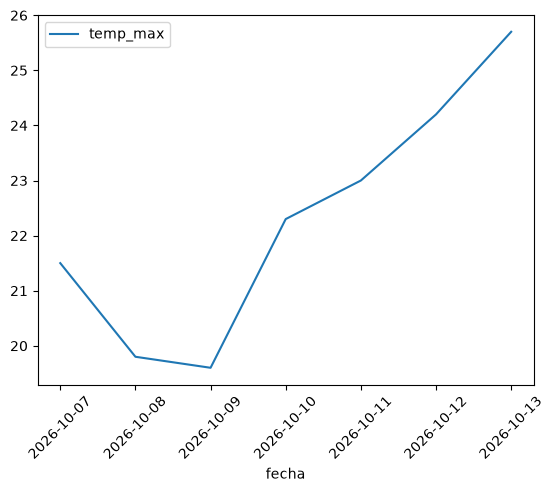

In [27]:
prevision.plot(x="fecha", y="temp_max", rot=45)  # hacemos un gráfico de la temperatura máxima de cada día, con las fechas en el eje X y rotadas 45º para que se lean mejor

<Axes: xlabel='fecha'>

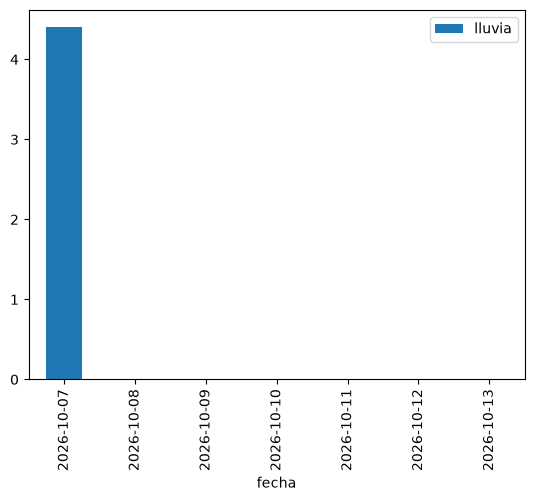

In [28]:
prevision.plot(x="fecha", y="lluvia", kind="bar")  # dibujamos un gráfico de barras con la cantidad de lluvia de cada día

## Ejercicios 1: el tiempo en tu ciudad

Coordenadas de algunas ciudades. Si la tuya no está, búscala en Google Maps y haz clic derecho sobre el sitio: el primer número es la latitud y el segundo la longitud.

| Ciudad | Latitud | Longitud | Ciudad | Latitud | Longitud | Ciudad | Latitud | Longitud |
|---|---|---|---|---|---|---|---|---|
| A Coruña | 43.37 | -8.40 | Granada | 37.19 | -3.61 | Santa Cruz de Tenerife | 28.47 | -16.25 |
| Alicante | 38.35 | -0.48 | Las Palmas de Gran Canaria | 28.10 | -15.42 | Santander | 43.47 | -3.80 |
| Almería | 36.84 | -2.46 | Logroño | 42.47 | -2.45 | Sevilla | 37.38 | -5.97 |
| Badajoz | 38.88 | -6.97 | Madrid | 40.42 | -3.70 | Tarragona | 41.12 | 1.25 |
| Barcelona | 41.39 | 2.16 | Málaga | 36.72 | -4.42 | Toledo | 39.86 | -4.02 |
| Bilbao | 43.26 | -2.93 | Murcia | 37.99 | -1.13 | Valencia | 39.47 | -0.38 |
| Cádiz | 36.53 | -6.29 | Oviedo | 43.36 | -5.84 | Valladolid | 41.66 | -4.72 |
| Córdoba | 37.89 | -4.77 | Palma | 39.57 | 2.65 | Vigo | 42.23 | -8.72 |
| Gijón | 43.54 | -5.66 | Pamplona | 42.82 | -1.64 | Vitoria | 42.85 | -2.67 |
| Girona | 41.98 | 2.82 | Salamanca | 40.97 | -5.66 | Zaragoza | 41.66 | -0.88 |

**1.1** Copia la primera celda de la sección 2 (la de la URL) y cambia `latitud` y `longitud` por las de tu ciudad. Ejecútala y haz clic en la URL que sale: tiene que descargarse un fichero.

In [31]:
latitud = "40.42"
longitud = "-3.70"

url = "https://api.open-meteo.com/v1/forecast"                                   # a quién se lo pedimos
url = url + "?latitude=" + latitud                                               # dónde: la latitud...
url = url + "&longitude=" + longitud                                             # ...y la longitud
url = url + "&daily=temperature_2m_max,temperature_2m_min,precipitation_sum"     # qué: máxima, mínima y lluvia de cada día
url = url + "&timezone=auto"                                                     # con la hora de ese sitio
url = url + "&format=csv"                                                        # en CSV, para leerlo con pandas


**1.2** Carga los datos de esa URL en una tabla `mi_ciudad` (sin olvidar `skiprows=3`) y enséñala.

Resultado esperado: una tabla de 7 filas

In [32]:
import pandas as pd

mi_ciudad = pd.read_csv(url, skiprows=3)
mi_ciudad

,time,temperature_2m_max (°C),temperature_2m_min (°C),precipitation_sum (mm)
0,2026-10-07,21.5,13.9,4.4
1,2026-10-08,19.8,12.9,0.0
2,2026-10-09,19.6,7.0,0.0
3,2026-10-10,22.3,8.5,0.0
4,2026-10-11,23.0,10.6,0.0
5,2026-10-12,24.2,10.9,0.0
6,2026-10-13,25.7,12.5,0.0


**1.3** Ponle a `mi_ciudad` nombres cortos a las columnas:import pandas as pd

In [33]:
mi_ciudad.columns = ["fecha", "temp_max", "temp_min", "lluvia"]
mi_ciudad

,fecha,temp_max,temp_min,lluvia
0,2026-10-07,21.5,13.9,4.4
1,2026-10-08,19.8,12.9,0.0
2,2026-10-09,19.6,7.0,0.0
3,2026-10-10,22.3,8.5,0.0
4,2026-10-11,23.0,10.6,0.0
5,2026-10-12,24.2,10.9,0.0
6,2026-10-13,25.7,12.5,0.0


**1.4** ¿Cuál será la temperatura más alta de la semana en tu ciudad?

In [34]:
print("Máxima de la semana:", mi_ciudad["temp_max"].max())

Máxima de la semana: 25.7


**1.5** ¿Y la más baja? Mira en la columna `temp_min`.

In [35]:
print("Mínima de la semana:", mi_ciudad["temp_min"].min())

Mínima de la semana: 7.0


**1.6** ¿Cuál es la media de las máximas de la semana? Redondéala a 1 decimal.

In [36]:
media = mi_ciudad["temp_max"].mean()
media = round(media, 1)
print("Media de las máximas:", media)

Media de las máximas: 22.3


**1.7** ¿Qué día hará más calor?

In [37]:
maxima = mi_ciudad["temp_max"].max()
dia_caluroso = mi_ciudad[mi_ciudad["temp_max"] == maxima]
dia_caluroso

,fecha,temp_max,temp_min,lluvia
6,2026-10-13,25.7,12.5,0.0


**1.8** ¿Cuántos días va a llover? Enseña esos días. Si no llueve ninguno, sale 0 y una tabla vacía.

In [38]:
dias_lluvia = mi_ciudad[mi_ciudad["lluvia"] > 0]
print("Días con lluvia:", len(dias_lluvia))
dias_lluvia

Días con lluvia: 1


,fecha,temp_max,temp_min,lluvia
0,2026-10-07,21.5,13.9,4.4


**1.9** Guarda `mi_ciudad` en un fichero con el nombre de tu ciudad (por ejemplo `sevilla.csv`).

In [39]:
mi_ciudad.to_csv("sevilla.csv", index=False)
print("Guardado")

Guardado


**1.10** Dibuja en un gráfico la máxima y la mínima de la semana.

<Axes: xlabel='fecha'>

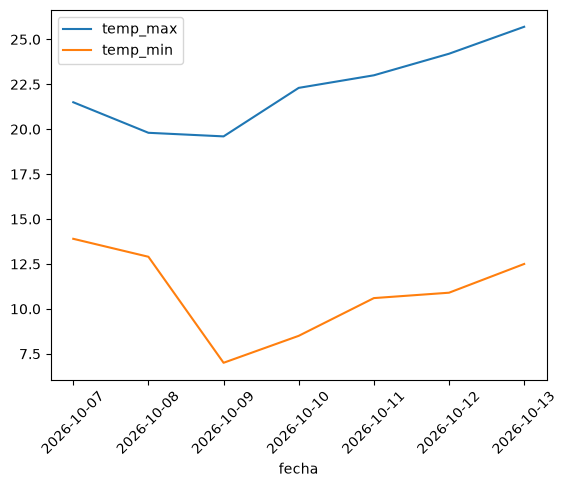

In [40]:
mi_ciudad.plot(x="fecha", y=["temp_max", "temp_min"], rot=45)

**1.11** Añade a `mi_ciudad` una columna `temp_media` con la temperatura media de cada día: la máxima más la mínima, dividido entre 2.

In [42]:
mi_ciudad["temp_media"] = (mi_ciudad["temp_max"] + mi_ciudad["temp_min"]) / 2
mi_ciudad

,fecha,temp_max,temp_min,lluvia,temp_media
0,2026-10-07,21.5,13.9,4.4,17.70
1,2026-10-08,19.8,12.9,0.0,16.35
2,2026-10-09,19.6,7.0,0.0,13.30
3,2026-10-10,22.3,8.5,0.0,15.40
4,2026-10-11,23.0,10.6,0.0,16.80
5,2026-10-12,24.2,10.9,0.0,17.55
6,2026-10-13,25.7,12.5,0.0,19.10


**1.12** Un día es de terraza si no llueve y la máxima pasa de 20 grados. ¿Cuántos días de terraza tendrá tu ciudad esta semana?

Para juntar dos condiciones en pandas se usa `&` y cada condición va entre paréntesis: `tabla[(condición 1) & (condición 2)]`

In [47]:
terraza = mi_ciudad[(mi_ciudad["lluvia"] == 0) & (mi_ciudad["temp_max"] > 20)]
len(terraza)

4

**1.13** Carga la previsión de otra ciudad en una tabla `otra` y compara la media de las máximas de las dos. Usa un `if` para escribir en cuál hará más calor.

In [49]:
# 1. URL de la otra ciudad (coordenadas entre comillas, como texto)
latitud_otra = "37.38"
longitud_otra = "-5.97"

url_otra = "https://api.open-meteo.com/v1/forecast"
url_otra = url_otra + "?latitude=" + latitud_otra
url_otra = url_otra + "&longitude=" + longitud_otra
url_otra = url_otra + "&daily=temperature_2m_max,temperature_2m_min,precipitation_sum"
url_otra = url_otra + "&timezone=auto"
url_otra = url_otra + "&format=csv"

# 2. Cargar la tabla y poner los mismos nombres de columnas que en mi_ciudad
otra = pd.read_csv(url_otra, skiprows=3)
otra.columns = ["fecha", "temp_max", "temp_min", "lluvia"]

# 3. Comparar la media de las máximas
media_mia = mi_ciudad["temp_max"].mean()
media_otra = otra["temp_max"].mean()

print("Media de las máximas en mi ciudad:", round(media_mia, 1))
print("Media de las máximas en la otra ciudad:", round(media_otra, 1))

if media_mia > media_otra:
    print("Hará más calor en mi ciudad")
elif media_otra > media_mia:
    print("Hará más calor en la otra ciudad")
else:
    print("Hará el mismo calor en las dos")

Media de las máximas en mi ciudad: 22.3
Media de las máximas en la otra ciudad: 30.0
Hará más calor en la otra ciudad


## 5. La máquina del tiempo

Documentación: https://open-meteo.com/en/docs/historical-weather-api

In [50]:
latitud = "40.42"
longitud = "-3.70"
inicio = "2021-01-06" # fechas de inicio y final de la semana que queremos consultar
fin = "2021-01-12" # formato año-mes-dia

url = "https://archive-api.open-meteo.com/v1/archive"                      # otra API: el histórico
url = url + "?latitude=" + latitud
url = url + "&longitude=" + longitud
url = url + "&start_date=" + inicio                                        # desde...
url = url + "&end_date=" + fin                                             # ...hasta
url = url + "&daily=temperature_2m_max,temperature_2m_min,snowfall_sum"    # máxima, mínima y nieve (en cm)
url = url + "&timezone=auto"
url = url + "&format=csv"

print(url)

https://archive-api.open-meteo.com/v1/archive?latitude=40.42&longitude=-3.70&start_date=2021-01-06&end_date=2021-01-12&daily=temperature_2m_max,temperature_2m_min,snowfall_sum&timezone=auto&format=csv


In [51]:
filomena = pd.read_csv(url, skiprows=3)
filomena.columns = ["fecha", "temp_max", "temp_min", "nieve"]
filomena

,fecha,temp_max,temp_min,nieve
0,2021-01-06,5.8,-4.1,0.00
1,2021-01-07,2.5,-2.4,1.05
2,2021-01-08,1.4,-2.0,9.52
3,2021-01-09,0.6,-1.4,22.89
4,2021-01-10,3.7,-1.5,0.00
5,2021-01-11,5.8,-3.1,0.00
6,2021-01-12,4.0,-6.5,0.00


<Axes: xlabel='fecha'>

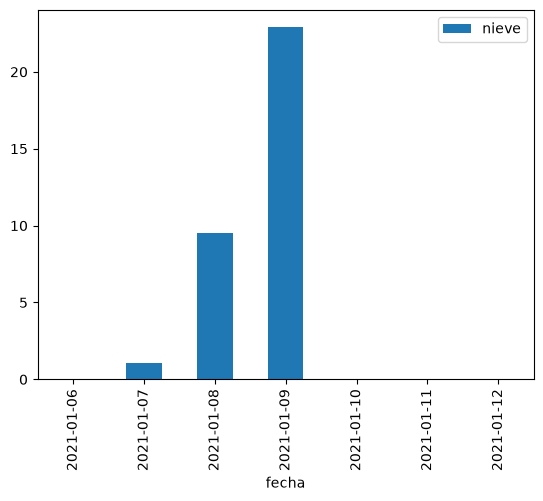

In [52]:
filomena.plot(x="fecha", y="nieve", kind="bar")  # dibujamos un gráfico de barras con la cantidad de nieve de cada día
 

In [53]:
latitud = "40.42"
longitud = "-3.70"
inicio = "2025-06-01" # fechas de inicio y final de la semana que queremos consultar
fin = "2025-08-31" # formato año-mes-dia

url = "https://archive-api.open-meteo.com/v1/archive"                      # otra API: el histórico
url = url + "?latitude=" + latitud
url = url + "&longitude=" + longitud
url = url + "&start_date=" + inicio                                        # desde...
url = url + "&end_date=" + fin                                             # ...hasta
url = url + "&daily=temperature_2m_max"
url = url + "&timezone=auto"
url = url + "&format=csv"

print(url)
 

https://archive-api.open-meteo.com/v1/archive?latitude=40.42&longitude=-3.70&start_date=2025-06-01&end_date=2025-08-31&daily=temperature_2m_max&timezone=auto&format=csv


In [54]:
verano_2025 = pd.read_csv(url, skiprows=3)
verano_2025.columns = ["fecha", "temp_max"]
verano_2025

,fecha,temp_max
0,2025-06-01,34.4
1,2025-06-02,31.9
2,2025-06-03,24.0
3,2025-06-04,25.3
4,2025-06-05,29.0
...,...,...
87,2025-08-27,32.8
88,2025-08-28,27.6
89,2025-08-29,29.7
90,2025-08-30,31.3


In [55]:
latitud = "40.42"
longitud = "-3.70"
inicio = "1975-06-01"
fin = "1975-08-31"

url = "https://archive-api.open-meteo.com/v1/archive"
url = url + "?latitude=" + latitud
url = url + "&longitude=" + longitud
url = url + "&start_date=" + inicio
url = url + "&end_date=" + fin
url = url + "&daily=temperature_2m_max"
url = url + "&timezone=auto"
url = url + "&format=csv"

print(url)

https://archive-api.open-meteo.com/v1/archive?latitude=40.42&longitude=-3.70&start_date=1975-06-01&end_date=1975-08-31&daily=temperature_2m_max&timezone=auto&format=csv


In [56]:
verano_1975 = pd.read_csv(url, skiprows=3)
verano_1975.columns = ["fecha", "temp_max"]
verano_1975

,fecha,temp_max
0,1975-06-01,18.0
1,1975-06-02,16.8
2,1975-06-03,21.3
3,1975-06-04,23.7
4,1975-06-05,27.1
...,...,...
87,1975-08-27,25.9
88,1975-08-28,26.4
89,1975-08-29,28.0
90,1975-08-30,30.5


In [57]:
calor_1975 = verano_1975[verano_1975["temp_max"] > 35]
print("Días de calor extremo en verano de 1975:", len(calor_1975))

Días de calor extremo en verano de 1975: 8


In [58]:
media_1975 = verano_1975["temp_max"].mean()
media_1975 = round(media_1975, 1)
media_2025 = verano_2025["temp_max"].mean()
media_2025 = round(media_2025, 1)

print("Media de las máximas en verano de 1975:", media_1975)
print("Media de las máximas en verano de 2025:", media_2025)

Media de las máximas en verano de 1975: 29.1
Media de las máximas en verano de 2025: 34.2


<Axes: >

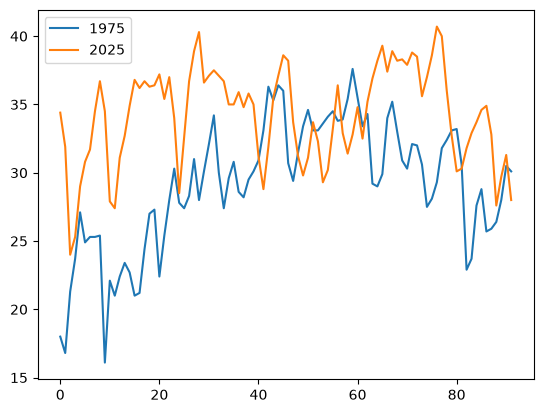

In [59]:
comparar = pd.DataFrame() #dataframe vacío para comparar los dos veranos

comparar["1975"] = verano_1975["temp_max"] # datos de 1975
comparar["2025"] = verano_2025["temp_max"] # datos de 2025
comparar.plot()

## Ejercicios 2: el pasado de tu ciudad

**2.1** ¿Qué tiempo hizo en tu ciudad el día que naciste, o un día que recuerdes? Copia la celda de la URL de Filomena (la primera de la sección 5) y cambia `latitud`, `longitud`, `inicio` y `fin`. Como es un solo día, `inicio` y `fin` llevan la misma fecha. Vale cualquier día desde 1940.

In [65]:
latitud = "40.42"
longitud = "-3.70"
inicio = "1997-02-12"
fin = "1997-02-12"

**2.2** Carga esos datos en una tabla `mi_dia`, ponle nombres cortos a las columnas y enséñala. Cuéntalo en el chat.

Resultado esperado: una tabla de 1 fila

**2.3** Copia la celda de la URL del verano de 2025 y cambia `latitud` y `longitud` por las de tu ciudad.

**2.4** Carga esos datos en una tabla `mi_verano_2025` y ponle nombres cortos a las columnas.

Resultado esperado: una tabla de 92 filas

**2.5** ¿Cuántos días pasó de 35 grados tu ciudad el verano pasado? Escríbelo en el chat. Si te sale 0, prueba con 30 grados.

**2.6** ¿Cuál fue la temperatura más alta de ese verano?

**2.7** Haz lo mismo con el verano de 1975 en tu ciudad: la URL y la tabla `mi_verano_1975`.

Resultado esperado: una tabla de 92 filas

**2.8** Compara la media de las máximas de los dos veranos.

**2.9** Dibuja los dos veranos de tu ciudad juntos en un gráfico.

**2.10** ¿Cuánto llovió en tu ciudad en 2025? Monta una URL con `inicio` y `fin` para el año entero y la línea de `daily` pidiendo `precipitation_sum`. Calcula el total del año con `.sum()`, cuántos días llovió y cuánto llovió el día que más.

Resultado esperado: una tabla de 365 filas

**2.11** Mini informe de tu ciudad. Elige un año y descarga la máxima, la mínima y la lluvia de todo el año (en `daily`: `temperature_2m_max,temperature_2m_min,precipitation_sum`). Guárdalo en un CSV y responde:

- ¿Cuál fue el día más caluroso? ¿Y el más frío?
- ¿Cuántos días llovió? ¿Cuánto llovió en total?
- ¿Cuántos días pasaron de 30 grados?

Termina con un gráfico de la máxima de todo el año.